In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

poscoil_tw = np.loadtxt('pos_tw.ser')        #read the writhe data file (usually writhe.ser)
poscoil_wr = np.loadtxt("pos_wr.ser")        #read the twist data file (usually tw.ser)

negcoil_tw = np.loadtxt('neg_tw.ser')        #read the writhe data file (usually writhe.ser)
negcoil_wr = np.loadtxt('neg_wr.ser')        #read the twist data file (usually tw.ser)

nocoil_tw = np.loadtxt('no_tw.ser')          #read the writhe data file (usually writhe.ser)
nocoil_wr = np.loadtxt('no_wr.ser')          #read the twist data file (usually tw.ser)


In [2]:
Tw = {
    'Positive' : poscoil_tw.sum(axis=-1)/360,
    'Negative' : negcoil_tw.sum(axis=-1)/360,
    'Normal' : nocoil_tw.sum(axis=-1)/360
}

Wr = {
    'Positive' : poscoil_wr[:,1],
    'Negative' : negcoil_wr[:,1],
    'Normal' : nocoil_wr[:,1]
}

Lk = {
    'Positive' : Tw['Positive'] + Wr['Positive'],
    'Negative' : Tw['Negative'] + Wr['Negative'],
    'Normal' : Tw['Normal'] + Wr['Normal']
    
}

In [3]:
def plot_multiple_with_shared_kde(ax, datasets,
                                  window=51,
                                  colors=None,
                                  labels=None,
                                  xlab=None,
                                  ylab=None):

    if colors is None:
        colors = ['purple', 'green', 'orange']
    if labels is None:
        labels = [f"Data {i+1}" for i in range(len(datasets))]

    kde_data = []

    # ---- LEFT: Plot time series ----
    for i, Z in enumerate(datasets):

        y = np.asarray(Z, dtype=float)
        frames = np.arange(1, len(y) + 1)  # FIX: generate per-dataset frames

        mask = np.isfinite(y)
        y = y[mask]
        frames = frames[mask]

        ax.plot(frames, y,
                color=colors[i],
                alpha=0.25,
                label=labels[i])

        # Moving average
        if window > 1 and len(y) >= window:
            kernel = np.ones(window)/window
            y_smooth = np.convolve(y, kernel, mode='valid')
            pad = (window - 1)//2
            ax.plot(frames[pad:pad+len(y_smooth)],
                    y_smooth,
                    color=colors[i],
                    linewidth=2)

        if len(y) > 1 and np.std(y) > 0:
            kde_data.append(y)

    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.legend(loc=3)

    # ---- RIGHT: Shared KDE ----
    if len(kde_data) == 0:
        return ax, None

    ax2 = ax.twinx()

    # Common y range
    all_y = np.concatenate(kde_data)
    y_grid = np.linspace(all_y.min(), all_y.max(), 400)

    x_min, x_max = ax.get_xlim()
    width = (x_max - x_min) * 0.15

    for i, y in enumerate(kde_data):

        kde = gaussian_kde(y)
        density = kde(y_grid)
        density /= density.max()

        kde_x = x_max + density * width

        ax2.plot(kde_x, y_grid,
                 color=colors[i],
                 lw=2)

        ax2.fill_betweenx(y_grid,
                          x_max,
                          kde_x,
                          color=colors[i],
                          alpha=0.2)

    ax2.set_yticks([])
    ax2.set_ylabel("")

    return ax, ax2


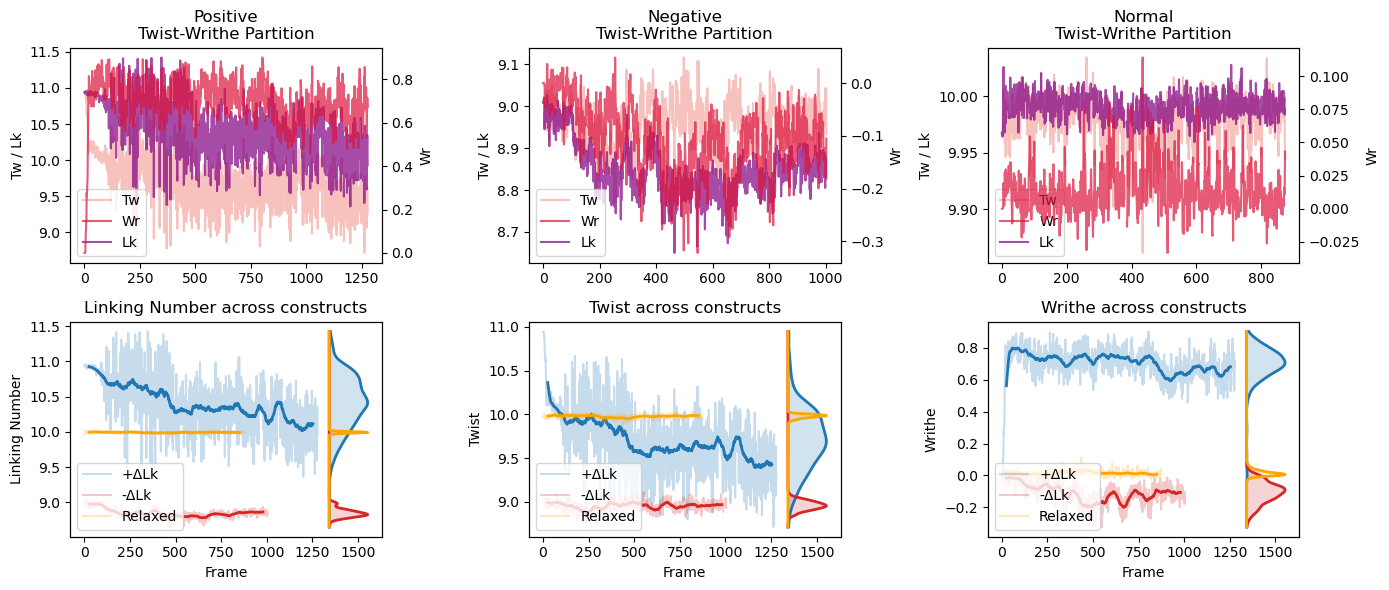

In [8]:
fig, axs = plt.subplots(2,3,figsize=(14,6))
axs = axs.flatten()

for i,case in enumerate(['Positive','Negative','Normal',('Linking Number', Lk),('Twist', Tw), ('Writhe', Wr)]):
    
    if i>2:
        plot_multiple_with_shared_kde(
            axs[i],
            datasets=[case[-1]['Positive'], case[-1]['Negative'], case[-1]['Normal']],
            colors=['#1f77b4', '#d62728', 'orange'],
            labels=['+ΔLk', '-ΔLk', 'Relaxed'],
            xlab="Frame",
            ylab=case[0]
        )

        axs[i].set_title(f'{case[0]} across constructs')

    else:
        l1, = axs[i].plot(Tw[case], label="Tw",color='#F4A7A3',alpha=0.7)
        #axs[i].set_ylabel("Tw")
        
        axs2 = axs[i].twinx()
        l2, = axs2.plot(Wr[case], label="Wr",color='crimson',alpha=0.7)
        axs2.set_ylabel("Wr")
    
        l3, = axs[i].plot(Lk[case], label="Lk",color='purple',alpha=0.7)
        axs[i].set_ylabel("Tw / Lk")
    
        axs[i].set_title(f'{case}\nTwist-Writhe Partition')
        axs[i].legend(handles=[l1, l2,l3], loc=3)

plt.tight_layout()

plt.savefig('Twist-Writhe-Lk-Analysis.jpeg',dpi=600)
